In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

df = pd.read_csv("course_lead_scoring_2026.csv")
print(df.shape)
display(df.head())

(5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [4]:

print(df.isnull().sum())


categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()


for col in categorical_columns:
    df[col] = df[col].fillna("NA")

for col in numerical_columns:
    df[col] = df[col].fillna(0.0)


df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

y_train = df_train["converted"]
y_val = df_val["converted"]
y_test = df_test["converted"]

X_train = df_train.drop(columns=["converted"])
X_val = df_val.drop(columns=["converted"])
X_test = df_test.drop(columns=["converted"])

print("Train:", len(df_train))
print("Validation:", len(df_val))
print("Test:", len(df_test))

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64
Train: 3000
Validation: 1000
Test: 1000


In [5]:
from sklearn.metrics import roc_auc_score

numerical_features = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income"
]

for feature in numerical_features:
    auc = roc_auc_score(y_train, X_train[feature])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -X_train[feature])

    print(feature, round(auc, 3))

lead_score 0.788
number_of_courses_viewed 0.723
interaction_count 0.765
annual_income 0.608


In [6]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

dv = DictVectorizer(sparse=True)

X_train_encoded = dv.fit_transform(
    X_train.to_dict(orient="records")
)

X_val_encoded = dv.transform(
    X_val.to_dict(orient="records")
)

model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000
)

model.fit(X_train_encoded, y_train)

y_pred_proba = model.predict_proba(X_val_encoded)[:, 1]

auc = roc_auc_score(y_val, y_pred_proba)

print("Validation ROC AUC:", round(auc, 3))

Validation ROC AUC: 0.732


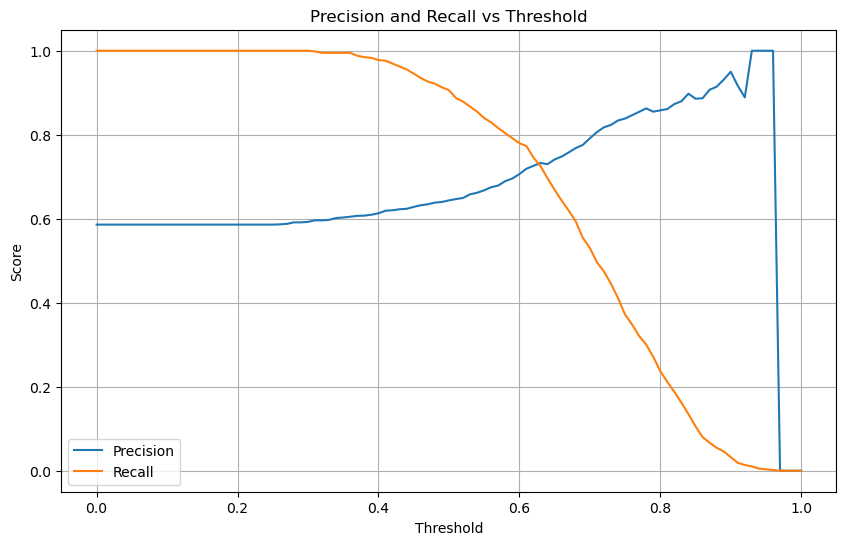

Threshold: 0.63
Precision: 0.7327586206896551
Recall: 0.7252559726962458


In [8]:
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0, 1.01, 0.01)

precision_values = []
recall_values = []

for threshold in thresholds:
    y_pred = (y_pred_proba >= threshold).astype(int)

    precision = precision_score(
        y_val, y_pred, zero_division=0
    )

    recall = recall_score(
        y_val, y_pred, zero_division=0
    )

    precision_values.append(precision)
    recall_values.append(recall)

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision_values, label="Precision")
plt.plot(thresholds, recall_values, label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall vs Threshold")
plt.legend()
plt.grid(True)
plt.show()
differences = np.abs(
    np.array(precision_values) - np.array(recall_values)
)

valid = ~(
    (np.array(precision_values) == 0) &
    (np.array(recall_values) == 0)
)

best_intersection_idx = np.argmin(
    np.where(valid, differences, np.inf)
)

print("Threshold:", thresholds[best_intersection_idx])
print("Precision:", precision_values[best_intersection_idx])
print("Recall:", recall_values[best_intersection_idx])


Best threshold: 0.41000000000000003
Maximum F1: 0.7576158940397351


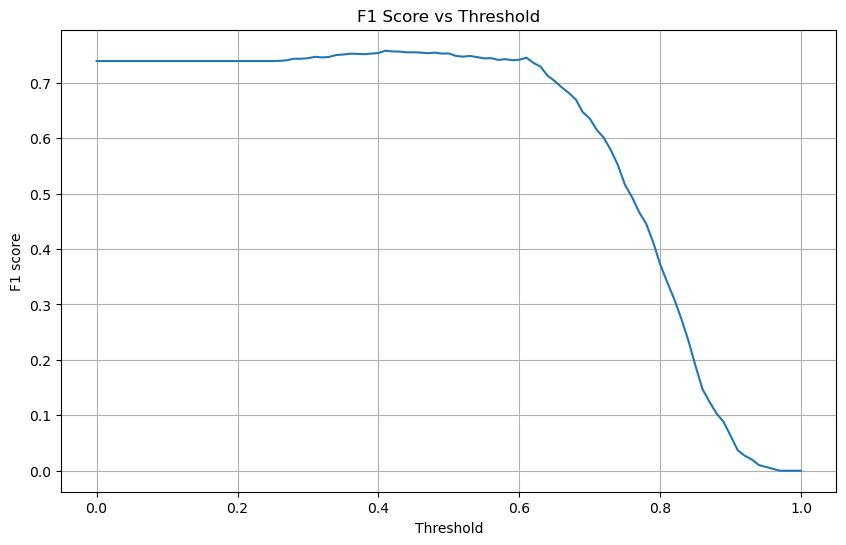

In [10]:
from sklearn.metrics import f1_score

f1_values = []

for threshold in thresholds:
    y_pred = (y_pred_proba >= threshold).astype(int)

    f1 = f1_score(y_val, y_pred, zero_division=0)

    f1_values.append(f1)

best_f1_idx = np.argmax(f1_values)

print("Best threshold:", thresholds[best_f1_idx])
print("Maximum F1:", f1_values[best_f1_idx])
plt.figure(figsize=(10, 6))
plt.plot(thresholds, f1_values)
plt.xlabel("Threshold")
plt.ylabel("F1 score")
plt.title("F1 Score vs Threshold")
plt.grid(True)
plt.show()


In [21]:
from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

def evaluate_fold(train_df, val_df, C=1.0):
    y_tr = train_df["converted"]
    y_va = val_df["converted"]

    X_tr = train_df.drop(columns=["converted"])
    X_va = val_df.drop(columns=["converted"])

    dv_fold = DictVectorizer(sparse=True)

    X_tr_encoded = dv_fold.fit_transform(
        X_tr.to_dict(orient="records")
    )

    X_va_encoded = dv_fold.transform(
        X_va.to_dict(orient="records")
    )

    model_fold = LogisticRegression(
        solver="liblinear",
        C=C,
        max_iter=1000
    )

    model_fold.fit(X_tr_encoded, y_tr)

    probabilities = model_fold.predict_proba(
        X_va_encoded
    )[:, 1]

    return roc_auc_score(y_va, probabilities)


In [22]:
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    fold_train = df_full_train.iloc[train_idx]
    fold_val = df_full_train.iloc[val_idx]

    score = evaluate_fold(fold_train, fold_val)
    scores.append(score)

print("Fold AUC scores:", scores)
print("Mean AUC:", np.mean(scores))
print("Standard deviation:", np.std(scores))
print("Rounded standard deviation:", round(np.std(scores), 3))

Fold AUC scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Mean AUC: 0.7317269710972524
Standard deviation: 0.006853233151022138
Rounded standard deviation: 0.007


In [23]:
C_values = [0.000001, 0.001, 1]

cv_results = []

for C in C_values:
    scores_C = []

    for train_idx, val_idx in kfold.split(df_full_train):
        fold_train = df_full_train.iloc[train_idx]
        fold_val = df_full_train.iloc[val_idx]

        score = evaluate_fold(
            fold_train,
            fold_val,
            C=C
        )

        scores_C.append(score)

    mean_auc = np.mean(scores_C)
    std_auc = np.std(scores_C)

    cv_results.append({
        "C": C,
        "mean_auc": round(mean_auc, 3),
        "std_auc": round(std_auc, 3)
    })

cv_results_df = pd.DataFrame(cv_results)
display(cv_results_df)

,C,mean_auc,std_auc
0,0.000001,0.617,0.019
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007
